# Aplicación 1 — Audio: clasificación de sonidos con espectrogramas y CNN

**Objetivo:** construir un clasificador de sonidos de punta a punta en PyTorch.

El audio es una señal 1D (amplitud vs. tiempo). Aunque se puede procesar directamente, la práctica más común es
transformarlo en un **espectrograma Mel**: una representación 2D *tiempo × frecuencia* que imita cómo el oído
humano percibe el sonido. Una vez tenemos esa "imagen" del sonido, una red convolucional puede aprender patrones
(armónicos, barridos de frecuencia, golpes percusivos...).

**Contenido**
1. Generar un dataset sintético de 5 tipos de sonido (no requiere descargas).
2. Onda → espectrograma Mel en escala logarítmica con `torchaudio`.
3. Aumentación de datos con *SpecAugment* (enmascarar bandas de tiempo y frecuencia).
4. Entrenar una CNN 2D y evaluarla con una matriz de confusión.
5. Ideas para pasar a datos reales (`SPEECHCOMMANDS`, ESC-50, UrbanSound8K).

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| torchaudio:", torchaudio.__version__, "| device:", device)

PyTorch: 2.8.0+cu128 | torchaudio: 2.8.0+cu128 | device: cuda


## 1. Un dataset sintético de sonidos

Generamos clips de 1 segundo a 8 kHz. Cada clase tiene una "firma" acústica distinta, y a todos les sumamos ruido
de fondo con un nivel aleatorio para que la tarea no sea trivial:

| Clase | Descripción | Cómo se ve en el espectrograma |
|---|---|---|
| `tono` | una sola sinusoide | una línea horizontal |
| `acorde` | tres sinusoides (tríada mayor) | tres líneas horizontales |
| `chirp` | frecuencia que sube o baja en el tiempo | una línea diagonal |
| `ruido` | ruido filtrado en una banda | una mancha ancha |
| `percusion` | golpes cortos que decaen rápido | líneas verticales |

In [2]:
SR = 8000          # frecuencia de muestreo (Hz)
DURATION = 1.0     # segundos
N = int(SR * DURATION)
CLASSES = ["tono", "acorde", "chirp", "ruido", "percusion"]
t = torch.arange(N) / SR

def rand(a, b):
    return a + (b - a) * torch.rand(1).item()

def make_sound(label):
    if label == "tono":
        f = rand(200, 2000)
        x = torch.sin(2 * math.pi * f * t + rand(0, 6.28))
    elif label == "acorde":
        f = rand(150, 800)
        x = sum(torch.sin(2 * math.pi * f * r * t) for r in (1.0, 1.26, 1.5)) / 3   # tríada mayor
    elif label == "chirp":
        f0, f1 = rand(100, 3000), rand(100, 3000)
        phase = 2 * math.pi * (f0 * t + (f1 - f0) / (2 * DURATION) * t**2)    # frecuencia lineal en el tiempo
        x = torch.sin(phase)
    elif label == "ruido":
        noise = torch.randn(N)
        center, width = rand(300, 3000), rand(100, 600)
        spec = torch.fft.rfft(noise)
        freqs = torch.fft.rfftfreq(N, 1 / SR)
        spec = spec * torch.exp(-((freqs - center) / width) ** 2)             # filtro pasabanda gaussiano
        x = torch.fft.irfft(spec, n=N)
    elif label == "percusion":
        x = torch.zeros(N)
        n_hits = int(rand(2, 7))
        for _ in range(n_hits):
            start = int(rand(0, 0.9) * N)
            length = N - start
            env = torch.exp(-torch.arange(length) / (SR * rand(0.01, 0.05)))  # decaimiento exponencial
            x[start:] += torch.randn(length) * env
    x = x / (x.abs().max() + 1e-8)
    snr = rand(0.02, 0.3)                                                     # ruido de fondo
    x = x + snr * torch.randn(N)
    return (x * rand(0.3, 1.0)).float()

class SyntheticSounds(Dataset):
    def __init__(self, n_per_class, seed):
        g = torch.manual_seed(seed)
        self.waves, self.labels = [], []
        for y, name in enumerate(CLASSES):
            for _ in range(n_per_class):
                self.waves.append(make_sound(name))
                self.labels.append(y)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.waves[i], self.labels[i]

train_ds = SyntheticSounds(400, seed=1)
val_ds = SyntheticSounds(80, seed=2)
test_ds = SyntheticSounds(80, seed=3)
print(len(train_ds), len(val_ds), len(test_ds))

2000 400 400


## 2. De la onda al espectrograma Mel

- **STFT**: se divide la señal en ventanas cortas (aquí 256 muestras = 32 ms) y se calcula la FFT de cada una.
- **Banco de filtros Mel**: agrupa las frecuencias en bandas espaciadas como las percibe el oído (más resolución en graves).
- **Decibelios**: aplicamos logaritmo porque la energía del sonido varía en muchos órdenes de magnitud.

El resultado es un tensor `[1, n_mels, frames]` que tratamos como una imagen de un canal.

Forma del espectrograma: (1, 64, 126)


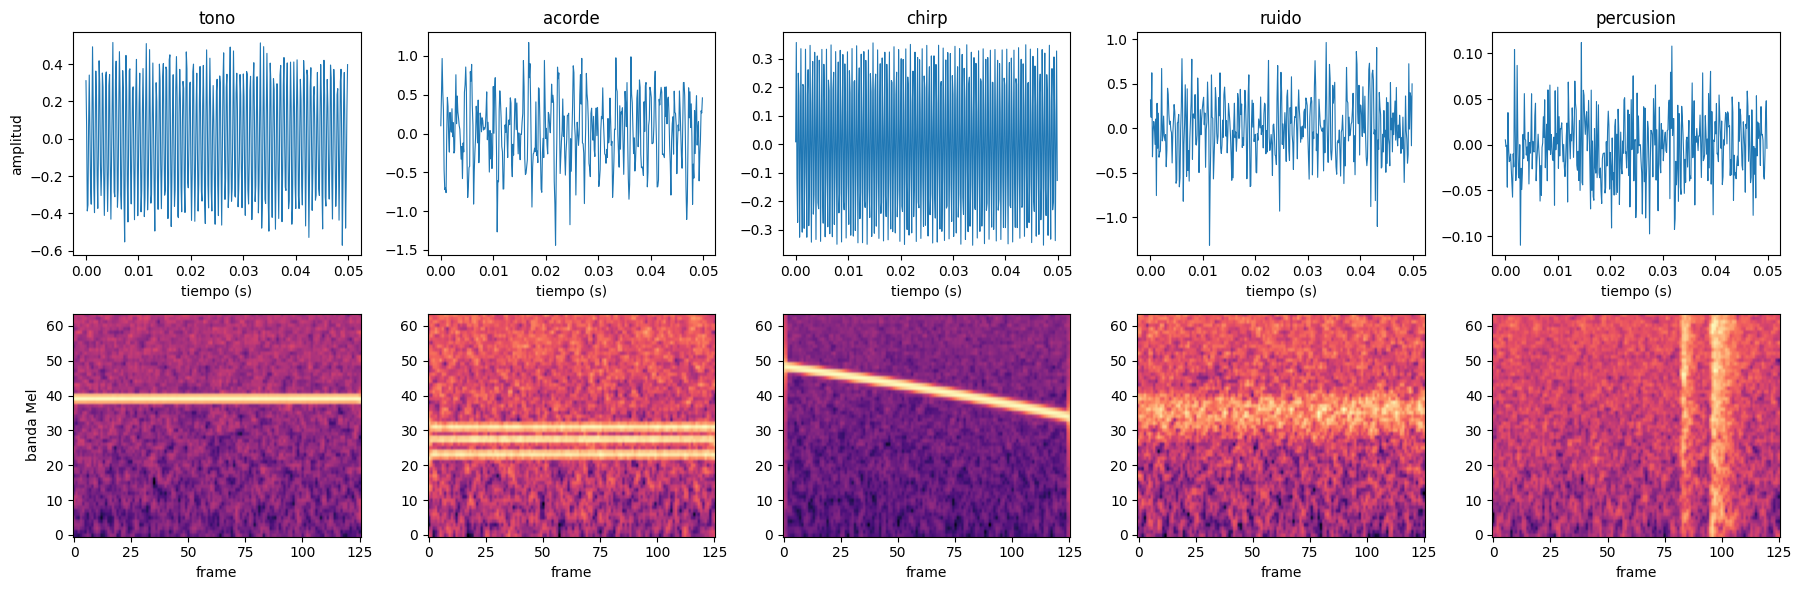

In [3]:
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=512, win_length=256,
                                           hop_length=64, n_mels=64)
to_db = torchaudio.transforms.AmplitudeToDB(top_db=80)

def featurize(wave):
    return to_db(mel(wave)).unsqueeze(0)       # [1, 64, frames]

example = featurize(train_ds[0][0])
print("Forma del espectrograma:", tuple(example.shape))

fig, axes = plt.subplots(2, len(CLASSES), figsize=(18, 6))
for c, name in enumerate(CLASSES):
    wave = train_ds[c * 400][0]
    axes[0, c].plot(t[:400], wave[:400], lw=0.8)        # primeros 50 ms
    axes[0, c].set_title(name)
    axes[0, c].set_xlabel("tiempo (s)")
    axes[1, c].imshow(featurize(wave)[0], origin="lower", aspect="auto", cmap="magma")
    axes[1, c].set_xlabel("frame")
axes[0, 0].set_ylabel("amplitud")
axes[1, 0].set_ylabel("banda Mel")
plt.tight_layout()
plt.show()

## 3. Aumentación con SpecAugment

Para que la red no memorice detalles irrelevantes, durante el entrenamiento ocultamos al azar una banda de
frecuencias y un intervalo de tiempo (Park et al., 2019, *SpecAugment*). Es la aumentación estándar en
reconocimiento de voz.

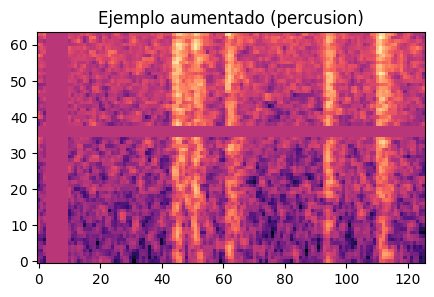

In [4]:
spec_augment = nn.Sequential(
    torchaudio.transforms.FrequencyMasking(freq_mask_param=8),
    torchaudio.transforms.TimeMasking(time_mask_param=20),
)

def collate(batch, augment=False):
    specs = torch.stack([featurize(w) for w, _ in batch])
    if augment:
        specs = spec_augment(specs)
    specs = (specs - specs.mean(dim=(2, 3), keepdim=True)) / (specs.std(dim=(2, 3), keepdim=True) + 1e-5)
    labels = torch.tensor([y for _, y in batch])
    return specs, labels

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=lambda b: collate(b, augment=True))
val_dl = DataLoader(val_ds, batch_size=128, collate_fn=collate)
test_dl = DataLoader(test_ds, batch_size=128, collate_fn=collate)

xb, yb = next(iter(train_dl))
plt.figure(figsize=(5, 3))
plt.imshow(xb[0, 0], origin="lower", aspect="auto", cmap="magma")
plt.title(f"Ejemplo aumentado ({CLASSES[yb[0]]})")
plt.show()

## 4. El modelo: una CNN 2D pequeña

Bloques `Conv → BatchNorm → ReLU → MaxPool` que reducen progresivamente la resolución, seguidos de un
*global average pooling*. Este último hace que la red funcione con clips de cualquier duración.

In [5]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.MaxPool2d(2),
    )

class AudioCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 16), conv_block(16, 32), conv_block(32, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

model = AudioCNN(len(CLASSES)).to(device)
print(f"Parámetros: {sum(p.numel() for p in model.parameters()):,}")

Parámetros: 72,565


In [6]:
def evaluate(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
EPOCHS = 12
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=EPOCHS * len(train_dl))
history = []
for epoch in range(EPOCHS):
    model.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
    tr_loss, tr_acc = evaluate(model, DataLoader(train_ds, batch_size=128, collate_fn=collate))
    va_loss, va_acc = evaluate(model, val_dl)
    history.append((tr_loss, va_loss, tr_acc, va_acc))
    print(f"época {epoch + 1:2d} | loss train {tr_loss:.3f} val {va_loss:.3f} | acc train {tr_acc:.3f} val {va_acc:.3f}")

época  1 | loss train 1.014 val 1.017 | acc train 0.540 val 0.535


época  2 | loss train 0.333 val 0.348 | acc train 0.898 val 0.873


época  3 | loss train 0.622 val 0.646 | acc train 0.688 val 0.657


época  4 | loss train 0.222 val 0.235 | acc train 0.903 val 0.897


época  5 | loss train 0.153 val 0.162 | acc train 0.939 val 0.922


...

época  8 | loss train 0.179 val 0.203 | acc train 0.938 val 0.922


época  9 | loss train 0.107 val 0.096 | acc train 0.964 val 0.963


época 10 | loss train 0.094 val 0.092 | acc train 0.967 val 0.970


época 11 | loss train 0.090 val 0.084 | acc train 0.974 val 0.983


época 12 | loss train 0.091 val 0.086 | acc train 0.972 val 0.980


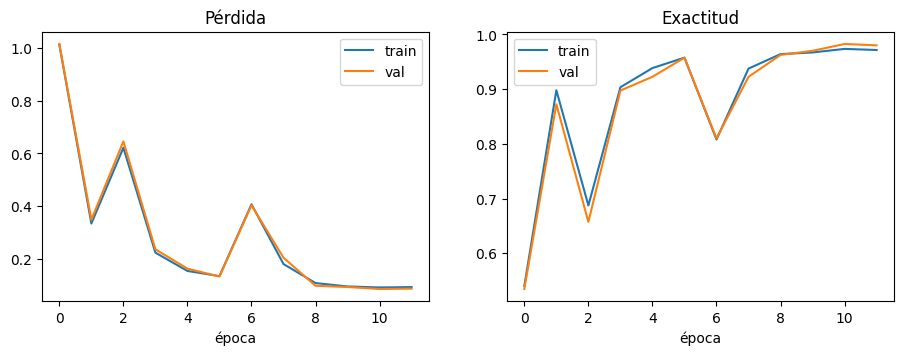

In [7]:
h = torch.tensor(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 1], label="val"); ax[0].set_title("Pérdida"); ax[0].legend()
ax[1].plot(h[:, 2], label="train"); ax[1].plot(h[:, 3], label="val"); ax[1].set_title("Exactitud"); ax[1].legend()
for a in ax: a.set_xlabel("época")
plt.show()

## 5. Evaluación en el conjunto de prueba

Exactitud en test: 0.973


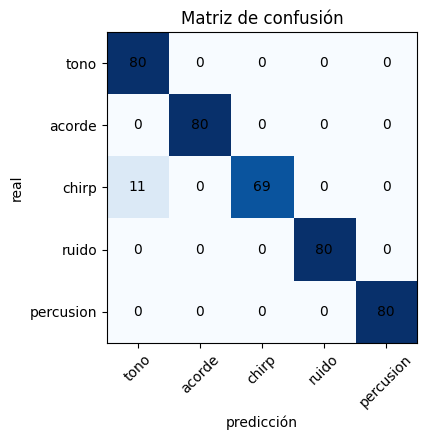

In [8]:
test_loss, test_acc = evaluate(model, test_dl)
print(f"Exactitud en test: {test_acc:.3f}")

confusion = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long)
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        pred = model(x.to(device)).argmax(1).cpu()
        for yt, yp in zip(y, pred):
            confusion[yt, yp] += 1

plt.figure(figsize=(5, 4.5))
plt.imshow(confusion, cmap="Blues")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=45); plt.yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, confusion[i, j].item(), ha="center", va="center")
plt.xlabel("predicción"); plt.ylabel("real"); plt.title("Matriz de confusión")
plt.tight_layout(); plt.show()

## 6. ¿Qué mira la red? Probando con sonidos nuevos

Generamos sonidos que la red nunca vio y mostramos la probabilidad asignada a cada clase.

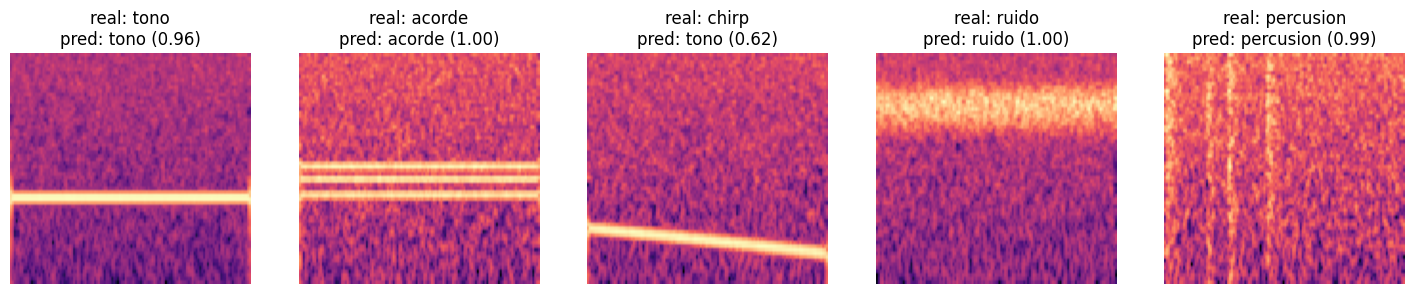

In [9]:
torch.manual_seed(123)
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
model.eval()
for ax, name in zip(axes, CLASSES):
    wave = make_sound(name)
    x, _ = collate([(wave, 0)])
    with torch.no_grad():
        probs = F.softmax(model(x.to(device)), dim=1)[0].cpu()
    ax.imshow(x[0, 0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"real: {name}\npred: {CLASSES[probs.argmax()]} ({probs.max():.2f})")
    ax.axis("off")
plt.show()

## 7. Siguientes pasos: datos reales

El mismo pipeline (onda → Mel → CNN) funciona con datos reales. Algunas opciones:

- **Speech Commands** (palabras habladas, 35 clases), incluido en torchaudio:
  ```python
  ds = torchaudio.datasets.SPEECHCOMMANDS("./data", download=True, subset="training")
  wave, sr, label, *_ = ds[0]       # sr = 16000
  ```
  Basta con ajustar `SR`, recortar/rellenar a 1 s y ampliar `n_mels`.
- **ESC-50** (sonidos ambientales) y **UrbanSound8K** (sonidos urbanos).
- Modelos preentrenados: `torchaudio.pipelines.WAV2VEC2_BASE` produce *embeddings* de voz que pueden usarse
  como características para tareas con pocos datos.

**Ejercicios**
1. Quita SpecAugment y compara la brecha entre train y validación.
2. Cambia la CNN 2D por una CNN 1D que opere directamente sobre la onda cruda. ¿Cuántas capas necesitas?
3. Añade una sexta clase (por ejemplo, un tono con *vibrato*) y observa qué clases se confunden.